# BÀI THỰC HÀNH 3: MẠNG NEURAL HỒI QUY CHO BÀI TOÁN PHÂN LOẠI VĂN BẢN VÀ GÁN NHÃN CHUỖI

Bộ dữ liệu sử dụng: [UIT-VSFC](https://drive.google.com/drive/folders/1rdcXNGt_3-QUvV8EtSvVsLMVeHmk6Yqk?usp=drive_link) và [PhoNERT](https://github.com/VinAIResearch/PhoNER_COVID19).

### Bài 1: Xây dựng mạng LSTM gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [14]:
%pip install -q numpy pandas scikit-learn matplotlib seaborn torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import copy
import random
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

SEED = 42
seed_all(SEED)

# Giới hạn số luồng CPU để tránh oversubscription.
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Thiết bị:", device)

PyTorch: 2.12.1+cpu
Thiết bị: cpu


In [16]:
from pathlib import Path
import pandas as pd

base = Path.cwd()
LAB = base / "Lab3" if (base / "Lab3").is_dir() else base

DATA = LAB / "data"
ART = LAB / "artifacts" / "uit_vsfc_sentiment"
ART.mkdir(parents=True, exist_ok=True)

print("Data directory:", DATA)
print("Artifacts directory:", ART)

Data directory: c:\Users\phucp\OneDrive\Desktop\DS201\Lab3\data
Artifacts directory: c:\Users\phucp\OneDrive\Desktop\DS201\Lab3\artifacts\uit_vsfc_sentiment


In [17]:
from pathlib import Path
import json

# Xác định thư mục dữ liệu
ROOT = Path.cwd()

if ROOT.name.lower() == "lab3":
    DATA_DIR = ROOT / "data" / "uit-vsfc"
elif (ROOT / "data" / "uit-vsfc").exists():
    DATA_DIR = ROOT / "data" / "uit-vsfc"
else:
    raise FileNotFoundError(
        f"Không tìm thấy thư mục UIT-VSFC. Current directory: {ROOT}"
    )

DATA_FILES = {
    "train": DATA_DIR / "UIT-VSFC-train.json",
    "dev": DATA_DIR / "UIT-VSFC-dev.json",
    "test": DATA_DIR / "UIT-VSFC-test.json"
}

# Khởi tạo và nạp dữ liệu
vsfc = {}

for split, path in DATA_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy file: {path}")

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # Chuẩn hóa cấu trúc dữ liệu
    if isinstance(data, dict):
        print(f"{split}: JSON có dạng dict, keys = {list(data.keys())}")
    elif isinstance(data, list):
        print(f"{split}: JSON có dạng list, số mẫu = {len(data)}")

    vsfc[split] = data

print("\nCác tập dữ liệu đã nạp:")
for split, data in vsfc.items():
    print(split, ":", len(data))

print("\nMẫu train:")
print(vsfc["train"][0])

train: JSON có dạng list, số mẫu = 11426
dev: JSON có dạng list, số mẫu = 1583
test: JSON có dạng list, số mẫu = 3166

Các tập dữ liệu đã nạp:
train : 11426
dev : 1583
test : 3166

Mẫu train:
{'sentence': 'slide giáo trình đầy đủ .', 'sentiment': 'positive', 'topic': 'training_program'}


In [18]:
from collections import Counter

PAD, UNK = 0, 1
def tokenize(text):
    return text.lower().split()

def build_vocab(sequences, min_freq=2):
    freq = Counter(t for tokens in sequences for t in tokens)
    tokens = sorted(t for t, n in freq.items() if n >= min_freq)
    return {"<pad>": PAD, "<unk>": UNK,
            **{t: i + 2 for i, t in enumerate(tokens)}}

vocab = build_vocab(tokenize(r["sentence"])
                    for r in vsfc["train"])
def encode(tokens, mapping):
    # Câu rỗng vẫn cần một bước để packing nhận length > 0.
    return [mapping.get(t, UNK) for t in tokens] or [UNK]

example = tokenize("giảng viên dạy rất hay")
print("Token minh họa:", example)
print("Chỉ số:", encode(example, vocab))
print("Kích thước từ điển train:", len(vocab))
assert vocab["<pad>"] == 0 and vocab["<unk>"] == 1

Token minh họa: ['giảng', 'viên', 'dạy', 'rất', 'hay']
Chỉ số: [394, 1313, 337, 978, 436]
Kích thước từ điển train: 1535


In [19]:
assert all(k in vsfc for k in ["train", "dev", "test"])

train_tokens = [
    tokenize(row["sentence"])
    for row in vsfc["train"]
]

vocab = build_vocab(train_tokens, min_freq=2)

print("Vocabulary size:", len(vocab))

Vocabulary size: 1535


In [20]:
import os
import time
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Cấu hình thực nghiệm
SEED = 42
PAD = 0
UNK = 1

EMBED_DIM = 300
HIDDEN_SIZE = 256
NUM_LAYERS = 5
DROPOUT = 0.3

BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

print("Device:", DEVICE)
print("Vocabulary size:", len(vocab))

Device: cpu
Vocabulary size: 1535


In [21]:
# Thứ tự nhãn cố định để kết quả dễ đọc
LABEL_NAMES = {
    "0": "negative",
    "1": "neutral",
    "2": "positive",
    "negative": "negative",
    "neutral": "neutral",
    "positive": "positive"
}

LABEL_TO_ID = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

ID_TO_LABEL = {
    value: key for key, value in LABEL_TO_ID.items()
}

def normalize_label(value):
    key = str(value).strip().lower()

    if key not in LABEL_NAMES:
        raise ValueError(f"Nhãn không hợp lệ: {value}")

    return LABEL_TO_ID[LABEL_NAMES[key]]

# Chuẩn hóa dữ liệu
for split in ["train", "dev", "test"]:
    for row in vsfc[split]:
        if "sentence" not in row or "sentiment" not in row:
            raise KeyError(
                f"{split} phải có trường sentence và sentiment. "
                f"Các trường hiện có: {list(row.keys())}"
            )

        row["sentence"] = str(row["sentence"])
        row["label_id"] = normalize_label(row["sentiment"])

print("Số lượng dữ liệu:")
for split in ["train", "dev", "test"]:
    print(f"{split}: {len(vsfc[split])}")

print("\nPhân bố nhãn train:")
print(pd.Series(
    [ID_TO_LABEL[r["label_id"]] for r in vsfc["train"]]
).value_counts())

Số lượng dữ liệu:
train: 11426
dev: 1583
test: 3166

Phân bố nhãn train:
positive    5643
negative    5325
neutral      458
Name: count, dtype: int64


In [22]:
print("PAD:", PAD)
print("UNK:", UNK)

print("Các token đặc biệt:")
print("<PAD>:", vocab.get("<PAD>"))
print("<UNK>:", vocab.get("<UNK>"))

print("\nCác từ có ID = 0:")
print([k for k, v in vocab.items() if v == 0])

print("\nCác từ có ID = 1:")
print([k for k, v in vocab.items() if v == 1])

PAD: 0
UNK: 1
Các token đặc biệt:
<PAD>: None
<UNK>: None

Các từ có ID = 0:
['<pad>']

Các từ có ID = 1:
['<unk>']


In [23]:
# Không sửa vocabulary gốc.
# Dùng hai ID mới, không trùng với bất kỳ token nào.
PAD_ID = max(vocab.values()) + 1
UNK_ID = PAD_ID + 1

print("PAD_ID:", PAD_ID)
print("UNK_ID:", UNK_ID)
print("Vocabulary size:", len(vocab))
print("Embedding size:", max(vocab.values()) + 1 + 2)

PAD_ID: 1535
UNK_ID: 1536
Vocabulary size: 1535
Embedding size: 1537


In [24]:
def encode_sentence(sentence):
    tokens = tokenize(sentence)

    ids = [
        vocab.get(token, UNK_ID)
        for token in tokens
    ]

    return ids if ids else [UNK_ID]


class VSFCDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records[index]

        input_ids = encode_sentence(row["sentence"])
        label = row["label_id"]

        return (
            torch.tensor(input_ids, dtype=torch.long),
            torch.tensor(label, dtype=torch.long)
        )


def collate_fn(batch):
    sequences, labels = zip(*batch)

    lengths = torch.tensor(
        [len(seq) for seq in sequences],
        dtype=torch.long
    )

    padded_sequences = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=PAD_ID
    )

    labels = torch.stack(labels)

    return padded_sequences, lengths, labels

In [25]:
train_dataset = VSFCDataset(vsfc["train"])
dev_dataset = VSFCDataset(vsfc["dev"])
test_dataset = VSFCDataset(vsfc["test"])

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

In [26]:
xb, lengths, yb = next(iter(train_loader))

print("Input:", xb.shape)
print("Lengths:", lengths[:5])
print("Labels:", yb[:5])
print("Max token ID:", xb.max().item())
print("Embedding size:", UNK_ID + 1)

Input: torch.Size([32, 60])
Lengths: tensor([26,  9,  9, 11,  9])
Labels: tensor([0, 0, 2, 2, 2])
Max token ID: 1536
Embedding size: 1537


In [27]:
class LSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=300,
        hidden_size=256,
        num_layers=5,
        num_classes=3,
        dropout=0.3,
        padding_idx=0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=padding_idx
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, cell) = self.lstm(packed)

        final_hidden = hidden[-1]

        output = self.dropout(final_hidden)
        logits = self.fc(output)

        return logits

In [28]:
# Kiểm tra các cấu hình cần thiết
print("Vocabulary size:", len(vocab))
print("PAD_ID:", PAD_ID)
print("UNK_ID:", UNK_ID)
print("Device:", DEVICE)

# Khởi tạo mô hình
model = LSTMClassifier(
    vocab_size=UNK_ID + 1,
    embed_dim=EMBED_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    num_classes=3,
    dropout=DROPOUT,
    padding_idx=PAD_ID
).to(DEVICE)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Đếm tham số
num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nModel initialized successfully!")
print("Trainable parameters:", f"{num_params:,}")

Vocabulary size: 1535
PAD_ID: 1535
UNK_ID: 1536
Device: cpu

Model initialized successfully!
Trainable parameters: 3,138,607


In [29]:
xb, lengths, yb = next(iter(train_loader))

xb = xb.to(DEVICE)
yb = yb.to(DEVICE)

logits = model(xb, lengths)

print("Input shape:", xb.shape)
print("Output shape:", logits.shape)
print("Expected output:", (BATCH_SIZE, 3))
print("Number of parameters:", f"{num_params:,}")

assert logits.shape[1] == 3

Input shape: torch.Size([32, 62])
Output shape: torch.Size([32, 3])
Expected output: (32, 3)
Number of parameters: 3,138,607


In [30]:
def run_epoch(model, loader, criterion, optimizer=None):

    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for input_ids, lengths, labels in loader:

        input_ids = input_ids.to(DEVICE)
        labels = labels.to(DEVICE)

        if is_train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_train):

            logits = model(input_ids, lengths)

            loss = criterion(logits, labels)

            if is_train:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = torch.argmax(logits, dim=1)

        all_preds.extend(predictions.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(all_labels, all_preds)

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "predictions": np.array(all_preds),
        "labels": np.array(all_labels)
    }

In [31]:
history = []

best_dev_f1 = -1
best_epoch = 0
best_state = None

for epoch in range(1, EPOCHS + 1):

    start_time = time.time()

    # Training
    train_result = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    # Validation
    dev_result = run_epoch(
        model,
        dev_loader,
        criterion
    )

    epoch_time = time.time() - start_time

    history.append({
        "epoch": epoch,
        "train_loss": train_result["loss"],
        "dev_loss": dev_result["loss"],
        "train_accuracy": train_result["accuracy"],
        "dev_accuracy": dev_result["accuracy"],
        "train_f1": train_result["macro_f1"],
        "dev_f1": dev_result["macro_f1"],
        "epoch_time": epoch_time
    })

    # Lưu checkpoint tốt nhất
    if dev_result["macro_f1"] > best_dev_f1:

        best_dev_f1 = dev_result["macro_f1"]
        best_epoch = epoch

        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": best_state,
                "dev_macro_f1": best_dev_f1,
                "vocab": vocab,
                "pad_id": PAD_ID,
                "unk_id": UNK_ID
            },
            "best_lstm_vsfc.pt"
        )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_result['loss']:.4f} | "
        f"Dev Loss: {dev_result['loss']:.4f} | "
        f"Train F1: {train_result['macro_f1']:.4f} | "
        f"Dev F1: {dev_result['macro_f1']:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

print("\n===== TRAINING COMPLETED =====")
print("Best epoch:", best_epoch)
print("Best Dev Macro-F1:", round(best_dev_f1, 4))

Epoch 01/10 | Train Loss: 0.4198 | Dev Loss: 0.3127 | Train F1: 0.5795 | Dev F1: 0.6137 | Time: 237.36s
Epoch 02/10 | Train Loss: 0.2794 | Dev Loss: 0.2919 | Train F1: 0.6800 | Dev F1: 0.7189 | Time: 219.23s
Epoch 03/10 | Train Loss: 0.2367 | Dev Loss: 0.2731 | Train F1: 0.7591 | Dev F1: 0.7680 | Time: 211.14s
Epoch 04/10 | Train Loss: 0.1987 | Dev Loss: 0.2766 | Train F1: 0.8103 | Dev F1: 0.7752 | Time: 259.77s
Epoch 05/10 | Train Loss: 0.1721 | Dev Loss: 0.2834 | Train F1: 0.8450 | Dev F1: 0.7453 | Time: 215.74s
Epoch 06/10 | Train Loss: 0.1436 | Dev Loss: 0.2743 | Train F1: 0.8766 | Dev F1: 0.8117 | Time: 214.50s
Epoch 07/10 | Train Loss: 0.1218 | Dev Loss: 0.3100 | Train F1: 0.9038 | Dev F1: 0.7986 | Time: 238.56s
Epoch 08/10 | Train Loss: 0.1043 | Dev Loss: 0.2869 | Train F1: 0.9213 | Dev F1: 0.8003 | Time: 255.39s
Epoch 09/10 | Train Loss: 0.0890 | Dev Loss: 0.3018 | Train F1: 0.9366 | Dev F1: 0.7842 | Time: 290.12s
Epoch 10/10 | Train Loss: 0.0750 | Dev Loss: 0.3518 | Train F1: 

In [32]:
checkpoint = torch.load(
    "best_lstm_vsfc.pt",
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best Dev Macro-F1:", checkpoint["dev_macro_f1"])

Best epoch: 6
Best Dev Macro-F1: 0.8116534150697249


In [33]:
test_result = run_epoch(
    model,
    test_loader,
    criterion
)

y_test = test_result["labels"]
y_pred = test_result["predictions"]

test_accuracy = accuracy_score(y_test, y_pred)

test_precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("===== LSTM TEST RESULTS =====")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"Macro-F1 : {test_f1:.4f}")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=["negative", "neutral", "positive"],
    digits=4,
    zero_division=0
))

===== LSTM TEST RESULTS =====
Accuracy : 0.9002
Precision: 0.7749
Recall   : 0.7314
Macro-F1 : 0.7475

Classification Report:
              precision    recall  f1-score   support

    negative     0.9057    0.9411    0.9231      1409
     neutral     0.4955    0.3293    0.3957       167
    positive     0.9233    0.9239    0.9236      1590

    accuracy                         0.9002      3166
   macro avg     0.7749    0.7314    0.7475      3166
weighted avg     0.8929    0.9002    0.8955      3166



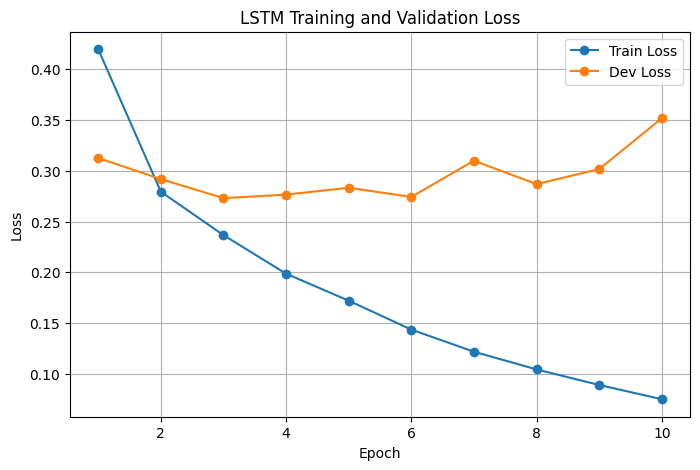

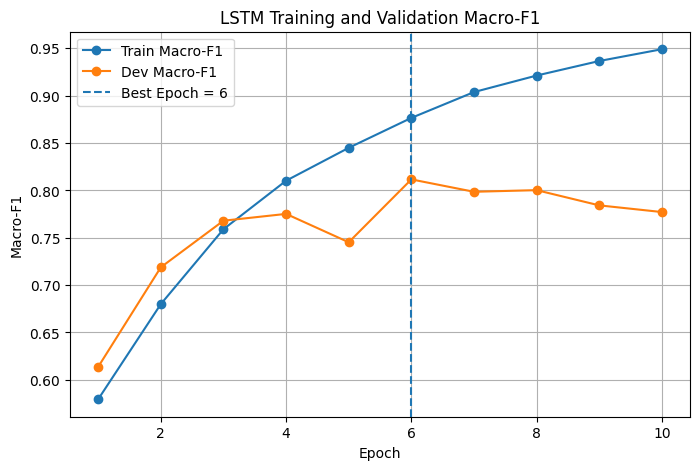

In [34]:
history_df = pd.DataFrame(history)

# Loss
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["dev_loss"],
    marker="o",
    label="Dev Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Macro-F1
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_f1"],
    marker="o",
    label="Train Macro-F1"
)

plt.plot(
    history_df["epoch"],
    history_df["dev_f1"],
    marker="o",
    label="Dev Macro-F1"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("LSTM Training and Validation Macro-F1")
plt.legend()
plt.grid(True)
plt.show()

In [35]:
summary_df = pd.DataFrame([
    ["Vocabulary size", len(vocab)],
    ["Embedding dimension", EMBED_DIM],
    ["Hidden size", HIDDEN_SIZE],
    ["Number of LSTM layers", NUM_LAYERS],
    ["Batch size", BATCH_SIZE],
    ["Learning rate", LEARNING_RATE],
    ["Number of epochs", EPOCHS],
    ["Best epoch", best_epoch],
    ["Trainable parameters", num_params],
    ["Average epoch time (seconds)", history_df["epoch_time"].mean()],
    ["Test Accuracy", test_accuracy],
    ["Test Precision", test_precision],
    ["Test Recall", test_recall],
    ["Test Macro-F1", test_f1]
], columns=["Metric", "Value"])

display(summary_df)

,Metric,Value
0,Vocabulary size,1.535000e+03
1,Embedding dimension,3.000000e+02
2,Hidden size,2.560000e+02
3,Number of LSTM layers,5.000000e+00
4,Batch size,3.200000e+01
5,Learning rate,1.000000e-03
6,Number of epochs,1.000000e+01
7,Best epoch,6.000000e+00
8,Trainable parameters,3.138607e+06
9,Average epoch time (seconds),2.370436e+02


In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import numpy as np

# Lấy dữ liệu từ cùng bộ chia đã dùng cho LSTM
X_train = [row["sentence"] for row in vsfc["train"]]
y_train = [row["label_id"] for row in vsfc["train"]]

X_dev = [row["sentence"] for row in vsfc["dev"]]
y_dev = [row["label_id"] for row in vsfc["dev"]]

X_test = [row["sentence"] for row in vsfc["test"]]
y_test = [row["label_id"] for row in vsfc["test"]]

# TF-IDF
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=50000,
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_dev_tfidf = tfidf.transform(X_dev)
X_test_tfidf = tfidf.transform(X_test)

print("Train:", X_train_tfidf.shape)
print("Dev:", X_dev_tfidf.shape)
print("Test:", X_test_tfidf.shape)

# Chọn C bằng Dev Macro-F1
best_c = None
best_dev_f1 = -1
best_tfidf_model = None

for c in [0.1, 1, 3, 10]:
    clf = LogisticRegression(
        C=c,
        max_iter=1000,
        solver="lbfgs"
    )

    clf.fit(X_train_tfidf, y_train)
    dev_pred = clf.predict(X_dev_tfidf)

    dev_f1 = f1_score(
        y_dev,
        dev_pred,
        average="macro"
    )

    print(f"C={c:<5} | Dev Macro-F1={dev_f1:.4f}")

    if dev_f1 > best_dev_f1:
        best_dev_f1 = dev_f1
        best_c = c
        best_tfidf_model = clf

print("\nBest C:", best_c)
print("Best Dev Macro-F1:", round(best_dev_f1, 4))

# Đánh giá mô hình đã chọn trên Test
tfidf_pred = best_tfidf_model.predict(X_test_tfidf)

print("\n===== TF-IDF TEST RESULTS =====")
print(f"Accuracy : {accuracy_score(y_test, tfidf_pred):.4f}")
print(f"Precision: {precision_score(y_test, tfidf_pred, average='macro', zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, tfidf_pred, average='macro', zero_division=0):.4f}")
print(f"Macro-F1 : {f1_score(y_test, tfidf_pred, average='macro', zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    tfidf_pred,
    labels=[0, 1, 2],
    target_names=["negative", "neutral", "positive"],
    digits=4,
    zero_division=0
))

Train: (11426, 13154)
Dev: (1583, 13154)
Test: (3166, 13154)
C=0.1   | Dev Macro-F1=0.6008
C=1     | Dev Macro-F1=0.6754
C=3     | Dev Macro-F1=0.7347
C=10    | Dev Macro-F1=0.7408

Best C: 10
Best Dev Macro-F1: 0.7408

===== TF-IDF TEST RESULTS =====
Accuracy : 0.8977
Precision: 0.8189
Recall   : 0.6929
Macro-F1 : 0.7159

Classification Report:
              precision    recall  f1-score   support

    negative     0.8749    0.9581    0.9146      1409
     neutral     0.6538    0.2036    0.3105       167
    positive     0.9281    0.9170    0.9225      1590

    accuracy                         0.8977      3166
   macro avg     0.8189    0.6929    0.7159      3166
weighted avg     0.8900    0.8977    0.8867      3166



In [37]:
import pandas as pd
import numpy as np

from sklearn.metrics import confusion_matrix

# Dự đoán trên Dev bằng mô hình TF-IDF tốt nhất
tfidf_dev_pred = best_tfidf_model.predict(X_dev_tfidf)

# Tên nhãn
label_names = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

# Tìm các mẫu dự đoán sai
wrong_indices = np.where(
    np.array(y_dev) != tfidf_dev_pred
)[0]

print("Total Dev samples:", len(y_dev))
print("Misclassified samples:", len(wrong_indices))
print("Dev Accuracy:", accuracy_score(y_dev, tfidf_dev_pred))
print("Dev Macro-F1:", f1_score(
    y_dev, tfidf_dev_pred, average="macro"
))

# Tạo bảng lỗi
error_data = []

for idx in wrong_indices:
    error_data.append({
        "index": idx,
        "sentence": X_dev[idx],
        "true_label": label_names[y_dev[idx]],
        "predicted_label": label_names[tfidf_dev_pred[idx]]
    })

error_df = pd.DataFrame(error_data)

# Ưu tiên hiển thị các lỗi liên quan đến Neutral
neutral_errors = error_df[
    (error_df["true_label"] == "neutral") |
    (error_df["predicted_label"] == "neutral")
]

display(neutral_errors.head(10))

Total Dev samples: 1583
Misclassified samples: 144
Dev Accuracy: 0.9090334807327859
Dev Macro-F1: 0.7408265247247536


,index,sentence,true_label,predicted_label
0,18,em không có bất cứ một lời phê bình nào .,neutral,negative
1,23,truyền đạt kiến thức .,neutral,positive
3,30,"thầy cho tự tìm hiểu , và tự tìm hiểu khác với...",neutral,negative
5,37,tạm được .,neutral,positive
8,71,"đồ án cuối kỳ trong vòng một tháng cuối , áp d...",positive,neutral
11,87,được 200 điểm là đươc 1 điểm quá trình .,neutral,negative
12,94,tài liệu được cấp thông qua lớp trưởng .,neutral,negative
15,117,sự nhiệt tình .,neutral,positive
16,127,cẩn thận .,neutral,positive
18,154,"theo như danh sách phòng đào tạo đưa xuống , l...",neutral,negative


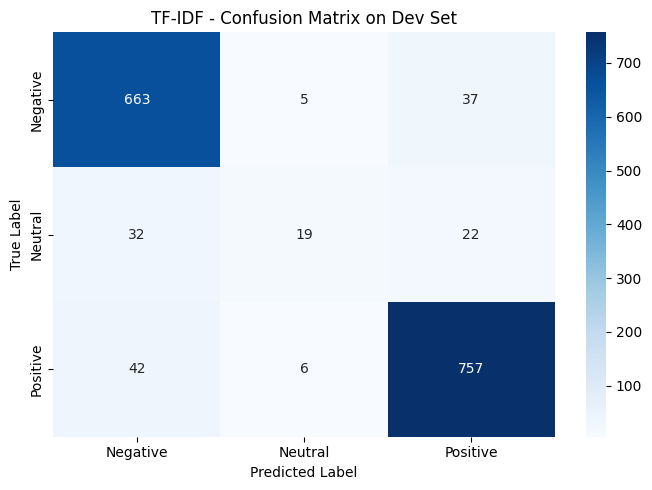

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_dev = confusion_matrix(
    y_dev,
    tfidf_dev_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dev,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("TF-IDF - Confusion Matrix on Dev Set")
plt.tight_layout()
plt.show()

In [39]:
# Lấy tối đa 3 lỗi có nhãn thực tế là Neutral
selected_errors = neutral_errors.head(3)

if len(selected_errors) < 3:
    remaining = error_df[
        ~error_df["index"].isin(selected_errors["index"])
    ]
    selected_errors = pd.concat([
        selected_errors,
        remaining.head(3 - len(selected_errors))
    ])

for i, (_, row) in enumerate(selected_errors.iterrows(), 1):
    print(f"\n===== ERROR CASE {i} =====")
    print("Sentence:", row["sentence"])
    print("True label:", row["true_label"])
    print("Predicted label:", row["predicted_label"])


===== ERROR CASE 1 =====
Sentence: em không có bất cứ một lời phê bình nào .
True label: neutral
Predicted label: negative

===== ERROR CASE 2 =====
Sentence: truyền đạt kiến thức .
True label: neutral
Predicted label: positive

===== ERROR CASE 3 =====
Sentence: thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề .
True label: neutral
Predicted label: negative


# Đánh giá mô hình LSTM

## 1. Kết quả đánh giá trên tập Test

Sau khi hoàn tất quá trình huấn luyện, mô hình LSTM được đánh giá trên tập Test gồm 3.166 mẫu. Kết quả thu được như sau:

| Metric | LSTM | TF-IDF + Logistic Regression |
|---|---:|---:|
| Accuracy | **0.9002** | 0.8977 |
| Precision-macro | 0.7749 | **0.8189** |
| Recall-macro | **0.7314** | 0.6929 |
| F1-macro | **0.7475** | 0.7159 |

### Nhận xét

- LSTM đạt Accuracy 90.02%, cao hơn một chút so với TF-IDF + Logistic Regression (89.77%).
- Macro-F1 của LSTM đạt 0.7475, cao hơn 0.7159 của TF-IDF, cho thấy khả năng phân loại cân bằng giữa các lớp được cải thiện.
- LSTM có Recall-macro cao hơn, thể hiện khả năng nhận diện các lớp tốt hơn xét trên trung bình.
- TF-IDF có Precision-macro cao hơn, nghĩa là các dự đoán của mô hình này có độ chính xác cao hơn khi xét trung bình từng lớp.

Nhìn chung, LSTM có kết quả tốt hơn TF-IDF + Logistic Regression về Accuracy, Recall-macro và F1-macro. Tuy nhiên, mức cải thiện Accuracy tương đối nhỏ.

## 2. F1-score từng lớp trên Test

Kết quả phân loại chi tiết của mô hình LSTM:

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Negative | 0.9057 | 0.9411 | **0.9231** | 1409 |
| Neutral | 0.4955 | 0.3293 | **0.3957** | 167 |
| Positive | 0.9233 | 0.9239 | **0.9236** | 1590 |
| Macro avg | 0.7749 | 0.7314 | 0.7475 | 3166 |
| Weighted avg | 0.8929 | 0.9002 | 0.8955 | 3166 |

### Phân tích

- **Negative:** Đạt F1-score 0.9231, cho thấy mô hình nhận diện khá tốt các câu mang sắc thái tiêu cực.
- **Neutral:** Chỉ đạt F1-score 0.3957, thấp hơn đáng kể so với hai lớp còn lại. Recall chỉ đạt 0.3293, nghĩa là mô hình bỏ sót nhiều mẫu trung lập.
- **Positive:** Đạt F1-score 0.9236, là lớp có kết quả tốt nhất trong ba lớp.

Một nguyên nhân quan trọng là sự mất cân bằng dữ liệu. Trong tập Test, lớp Neutral chỉ có 167 mẫu, trong khi Negative có 1.409 mẫu và Positive có 1.590 mẫu.

Do đó, mô hình có xu hướng học tốt hơn các đặc trưng của hai lớp chiếm đa số. Đây cũng là lý do Accuracy đạt 90.02% nhưng Macro-F1 chỉ đạt 74.75%.


## 3. Đường Loss và Macro-F1 qua các Epoch

Mô hình được huấn luyện trong 10 epochs. Kết quả chi tiết:

| Epoch | Train Loss | Dev Loss | Train F1 | Dev F1 | Time (s) |
|---:|---:|---:|---:|---:|---:|
| 1 | 0.4198 | 0.3127 | 0.5795 | 0.6137 | 237.36 |
| 2 | 0.2794 | 0.2919 | 0.6800 | 0.7189 | 219.23 |
| 3 | 0.2367 | 0.2731 | 0.7591 | 0.7680 | 211.14 |
| 4 | 0.1987 | 0.2766 | 0.8103 | 0.7752 | 259.77 |
| 5 | 0.1721 | 0.2834 | 0.8450 | 0.7453 | 215.74 |
| 6 | 0.1436 | 0.2743 | 0.8766 | **0.8117** | 214.50 |
| 7 | 0.1218 | 0.3100 | 0.9038 | 0.7986 | 238.56 |
| 8 | 0.1043 | 0.2869 | 0.9213 | 0.8003 | 255.39 |
| 9 | 0.0890 | 0.3018 | 0.9366 | 0.7842 | 290.12 |
| 10 | 0.0750 | 0.3518 | 0.9491 | 0.7772 | 228.62 |

**Kết quả tốt nhất:**

- Best epoch: 6
- Best Dev Macro-F1: 0.8117

### 3.1. Phân tích Loss

Train Loss giảm liên tục từ 0.4198 xuống 0.0750, cho thấy mô hình ngày càng tối ưu tốt trên tập huấn luyện.

Trong khi đó, Dev Loss giảm từ 0.3127 xuống mức thấp nhất 0.2731 tại epoch 3, sau đó dao động và tăng lên 0.3518 tại epoch 10.

Điều này cho thấy khả năng tổng quát hóa của mô hình không còn cải thiện tương ứng với kết quả trên tập huấn luyện.

### 3.2. Phân tích Macro-F1

Train Macro-F1 tăng liên tục từ 0.5795 lên 0.9491. Dev Macro-F1 cũng tăng trong những epoch đầu và đạt giá trị cao nhất 0.8117 tại epoch 6.

Sau epoch 6, Dev Macro-F1 có xu hướng giảm, mặc dù Train Macro-F1 vẫn tiếp tục tăng.

Khoảng cách giữa hai chỉ số ngày càng lớn cho thấy mô hình có dấu hiệu **Overfitting**. Mô hình ngày càng phù hợp với dữ liệu huấn luyện nhưng khả năng tổng quát hóa trên dữ liệu chưa từng thấy không còn được cải thiện.

Vì vậy, lựa chọn checkpoint tại epoch 6 là hợp lý. Việc sử dụng checkpoint tốt nhất giúp tránh sử dụng trọng số ở epoch cuối khi hiệu quả trên tập Dev đã suy giảm.

## 4. Số lượng tham số và thời gian huấn luyện

| Thông số | Giá trị |
|---|---:|
| Vocabulary size | 1,535 |
| Embedding dimension | 300 |
| Hidden size | 256 |
| Number of LSTM layers | 5 |
| Batch size | 32 |
| Learning rate | 0.001 |
| Number of epochs | 10 |
| Best epoch | 6 |
| Trainable parameters | **3,138,607** |
| Average epoch time | **237.04 giây** |

Thời gian trung bình mỗi epoch tương đương khoảng 3 phút 57 giây. Tổng thời gian huấn luyện 10 epochs khoảng 39 phút 30 giây.

Mô hình có hơn 3.1 triệu tham số, với 5 tầng LSTM và hidden size 256. Kiến trúc này có khả năng học các đặc trưng tuần tự của văn bản, tuy nhiên cũng làm tăng chi phí tính toán và nguy cơ overfitting.

## 5. Phân tích các trường hợp dự đoán sai trên Dev

Dựa trên kết quả dự đoán thực tế của mô hình LSTM trên tập Dev, có thể nhận thấy mô hình vẫn gặp khó khăn trong việc phân biệt lớp Neutral với hai lớp Negative và Positive.

### Trường hợp 1

- **Câu:** "em không có bất cứ một lời phê bình nào ."
- **Nhãn thực tế:** Neutral
- **Nhãn dự đoán:** Negative

**Phân tích:**

Câu văn chứa từ phủ định "không" và cụm từ "lời phê bình". Mô hình có thể đã học được mối liên hệ giữa các từ mang ý nghĩa phủ định hoặc phê bình với cảm xúc tiêu cực (Negative).

Tuy nhiên, xét trên toàn bộ ngữ cảnh, người nói chỉ đang khẳng định rằng mình không có lời phê bình nào, chứ không trực tiếp thể hiện thái độ tiêu cực.

Đây là trường hợp mô hình phụ thuộc nhiều vào các từ khóa riêng lẻ mà chưa nắm bắt đầy đủ ý nghĩa của cả câu.

### Trường hợp 2

- **Câu:** "truyền đạt kiến thức ."
- **Nhãn thực tế:** Neutral
- **Nhãn dự đoán:** Positive

**Phân tích:**

Câu văn chỉ mô tả một hoạt động truyền đạt kiến thức, không thể hiện rõ thái độ khen ngợi hay phê bình.

Mô hình có thể đã liên kết các từ như "truyền đạt" và "kiến thức" với những ngữ cảnh tích cực, chẳng hạn như đánh giá tốt về khả năng giảng dạy hoặc chất lượng giáo dục.

Tuy nhiên, bản thân câu này mang tính mô tả khách quan và không chứa dấu hiệu cảm xúc rõ ràng. Điều này cho thấy mô hình có xu hướng suy diễn cảm xúc tích cực từ những từ ngữ thường xuất hiện trong ngữ cảnh tích cực.

### Trường hợp 3

- **Câu:** "thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề ."
- **Nhãn thực tế:** Neutral
- **Nhãn dự đoán:** Negative

**Phân tích:**

Câu văn mang tính nhận xét và mô tả sự khác biệt giữa việc tự tìm hiểu với việc thực sự hiểu được vấn đề.

Mặc dù không trực tiếp sử dụng những từ ngữ tiêu cực, nội dung câu có thể xuất hiện trong ngữ cảnh góp ý hoặc chưa hài lòng về phương pháp giảng dạy.

Mô hình có thể đã học được mối liên hệ giữa các cụm từ như "tự tìm hiểu" và "khác với hiểu được vấn đề" với những ngữ cảnh phê bình, dẫn đến dự đoán nhãn Negative.

Tuy nhiên, câu văn chủ yếu trình bày một nhận định mang tính khách quan, chưa đủ cơ sở để xác định cảm xúc tiêu cực của người nói. Điều này cho thấy mô hình còn hạn chế trong việc phân biệt giữa nội dung nhận xét và sắc thái cảm xúc thực sự.

### 5.1. Nhận xét chung về các trường hợp dự đoán sai

Qua ba trường hợp trên, có thể rút ra một số hạn chế của mô hình LSTM:

- **Phụ thuộc vào từ khóa:** Mô hình có xu hướng dựa vào những từ ngữ mang sắc thái cảm xúc hoặc thường xuất hiện trong các ngữ cảnh tích cực, tiêu cực để đưa ra dự đoán.
- **Hạn chế trong việc hiểu ngữ cảnh:** Mô hình chưa phân biệt tốt giữa câu mô tả khách quan, câu nhận xét và câu thực sự thể hiện cảm xúc.
- **Khó nhận diện lớp Neutral:** Các câu trung lập thường không chứa dấu hiệu cảm xúc rõ ràng, khiến mô hình dễ phân loại nhầm sang Negative hoặc Positive.
- **Ảnh hưởng của mất cân bằng dữ liệu:** Lớp Neutral có số lượng mẫu thấp hơn đáng kể so với hai lớp còn lại, khiến mô hình có thể chưa học đầy đủ các đặc trưng của lớp này.

Nhìn chung, các trường hợp dự đoán sai cho thấy hạn chế lớn nhất của mô hình nằm ở khả năng nhận diện cảm xúc trung lập.

## 6. Kết luận

Mô hình LSTM đạt Accuracy 90.02% và Macro-F1 74.75% trên tập Test. Kết quả cho thấy mô hình có khả năng phân loại tốt đối với hai lớp Negative và Positive, với F1-score lần lượt là 0.9231 và 0.9236.

Tuy nhiên, hiệu quả phân loại lớp Neutral còn hạn chế, chỉ đạt F1-score 0.3957. Nguyên nhân có thể liên quan đến sự mất cân bằng dữ liệu và đặc điểm ngữ nghĩa của các câu trung lập.

Trong quá trình huấn luyện, mô hình đạt Dev Macro-F1 tốt nhất tại epoch 6 với giá trị 0.8117. Sau epoch này, Train F1 tiếp tục tăng trong khi Dev F1 giảm, cho thấy dấu hiệu overfitting. Vì vậy, sử dụng checkpoint tại epoch 6 là lựa chọn phù hợp.

So với TF-IDF kết hợp Logistic Regression, LSTM cải thiện Macro-F1 từ 0.7159 lên 0.7475. Điều này cho thấy mô hình LSTM có tiềm năng khai thác các đặc trưng tuần tự của văn bản để cải thiện hiệu quả phân loại cảm xúc.

Để cải thiện kết quả trong tương lai, có thể cân nhắc sử dụng class weighting hoặc oversampling nhằm giảm ảnh hưởng của mất cân bằng dữ liệu, tăng cường dữ liệu cho lớp Neutral và thử nghiệm các mô hình ngôn ngữ có khả năng biểu diễn ngữ cảnh tốt hơn.

Nhìn chung, LSTM cho kết quả khả quan về Accuracy và khả năng phân loại hai lớp cảm xúc chính, nhưng vẫn cần cải thiện khả năng nhận diện lớp Neutral để đạt hiệu quả phân loại cân bằng hơn.

### Bài 2: Xây dựng mạng GRU gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [40]:
import random
import time
import copy
import numpy as np
import torch
import torch.nn as nn

from torch.nn.utils.rnn import pack_padded_sequence

# =====================================================
# 1. Reset random seed - không tái sử dụng trạng thái LSTM
# =====================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# =====================================================
# 2. Định nghĩa TextClassifier
# =====================================================

class TextClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=300,
        hidden_size=256,
        num_layers=5,
        num_classes=3,
        dropout=0.3,
        padding_idx=0,
        kind="GRU"
    ):
        super().__init__()

        self.kind = kind.upper()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=padding_idx
        )

        if self.kind == "GRU":
            self.rnn = nn.GRU(
                input_size=embed_dim,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=dropout
            )
        elif self.kind == "LSTM":
            self.rnn = nn.LSTM(
                input_size=embed_dim,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=dropout
            )
        else:
            raise ValueError("kind phải là 'GRU' hoặc 'LSTM'")

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        if self.kind == "GRU":
            _, hidden = self.rnn(packed)
        else:
            _, (hidden, cell) = self.rnn(packed)

        # GRU và LSTM đều sử dụng hidden state tầng cuối
        final_hidden = hidden[-1]

        output = self.dropout(final_hidden)
        logits = self.fc(output)

        return logits


# =====================================================
# 3. Khởi tạo GRU mới
# =====================================================

EMBED_DIM = 300
HIDDEN_SIZE = 256
NUM_LAYERS = 5
NUM_CLASSES = 3
DROPOUT = 0.3
LEARNING_RATE = 1e-3
EPOCHS = 10

gru_model = TextClassifier(
    vocab_size=UNK_ID + 1,
    embed_dim=EMBED_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT,
    padding_idx=PAD_ID,
    kind="GRU"
).to(DEVICE)

criterion_gru = nn.CrossEntropyLoss()

optimizer_gru = torch.optim.Adam(
    gru_model.parameters(),
    lr=LEARNING_RATE
)

gru_params = sum(
    p.numel()
    for p in gru_model.parameters()
    if p.requires_grad
)

print("===== GRU CONFIGURATION =====")
print("Architecture: GRU")
print("Number of layers:", NUM_LAYERS)
print("Hidden size:", HIDDEN_SIZE)
print("Embedding dimension:", EMBED_DIM)
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)
print("Dropout:", DROPOUT)
print("Trainable parameters:", f"{gru_params:,}")
print("Device:", DEVICE)

===== GRU CONFIGURATION =====
Architecture: GRU
Number of layers: 5
Hidden size: 256
Embedding dimension: 300
Optimizer: Adam
Learning rate: 0.001
Dropout: 0.3
Trainable parameters: 2,469,423
Device: cpu


In [41]:
xb, lengths, yb = next(iter(train_loader))

xb = xb.to(DEVICE)
yb = yb.to(DEVICE)

gru_model.eval()

with torch.no_grad():
    logits = gru_model(xb, lengths)

print("Input shape:", xb.shape)
print("Output shape:", logits.shape)
print("Expected output shape:", (xb.size(0), 3))

Input shape: torch.Size([32, 71])
Output shape: torch.Size([32, 3])
Expected output shape: (32, 3)


In [42]:
# =====================================================
# GRU TRAINING
# =====================================================

gru_history = []

best_gru_f1 = -1
best_gru_epoch = 0

for epoch in range(EPOCHS):

    start_time = time.perf_counter()

    # Training
    train_result = run_epoch(
        model=gru_model,
        loader=train_loader,
        criterion=criterion_gru,
        optimizer=optimizer_gru
    )

    # Validation
    dev_result = run_epoch(
        model=gru_model,
        loader=dev_loader,
        criterion=criterion_gru,
        optimizer=None
    )

    epoch_time = time.perf_counter() - start_time

    train_loss = train_result["loss"]
    dev_loss = dev_result["loss"]

    train_f1 = train_result["macro_f1"]
    dev_f1 = dev_result["macro_f1"]

    gru_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "dev_loss": dev_loss,
        "train_f1": train_f1,
        "dev_f1": dev_f1,
        "epoch_time": epoch_time
    })

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Dev Loss: {dev_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Dev F1: {dev_f1:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

    # Lưu checkpoint tốt nhất theo Dev Macro-F1
    if dev_f1 > best_gru_f1:
        best_gru_f1 = dev_f1
        best_gru_epoch = epoch + 1

        torch.save(
            gru_model.state_dict(),
            "best_gru_vsfc.pt"
        )

print("\n===== GRU TRAINING COMPLETED =====")
print("Best epoch:", best_gru_epoch)
print("Best Dev Macro-F1:", best_gru_f1)

Epoch 01/10 | Train Loss: 0.3970 | Dev Loss: 0.3080 | Train F1: 0.5969 | Dev F1: 0.6755 | Time: 182.93s
Epoch 02/10 | Train Loss: 0.2647 | Dev Loss: 0.2638 | Train F1: 0.7240 | Dev F1: 0.7635 | Time: 166.77s
Epoch 03/10 | Train Loss: 0.2177 | Dev Loss: 0.2992 | Train F1: 0.7975 | Dev F1: 0.7418 | Time: 166.91s
Epoch 04/10 | Train Loss: 0.1778 | Dev Loss: 0.2885 | Train F1: 0.8378 | Dev F1: 0.7742 | Time: 167.70s
Epoch 05/10 | Train Loss: 0.1520 | Dev Loss: 0.2970 | Train F1: 0.8685 | Dev F1: 0.7693 | Time: 167.28s
Epoch 06/10 | Train Loss: 0.1280 | Dev Loss: 0.2966 | Train F1: 0.8962 | Dev F1: 0.7644 | Time: 165.79s
Epoch 07/10 | Train Loss: 0.1057 | Dev Loss: 0.3375 | Train F1: 0.9165 | Dev F1: 0.7911 | Time: 159.89s
Epoch 08/10 | Train Loss: 0.0907 | Dev Loss: 0.3691 | Train F1: 0.9276 | Dev F1: 0.7968 | Time: 168.64s
Epoch 09/10 | Train Loss: 0.0771 | Dev Loss: 0.3389 | Train F1: 0.9438 | Dev F1: 0.7881 | Time: 161.30s
Epoch 10/10 | Train Loss: 0.0774 | Dev Loss: 0.3653 | Train F1: 

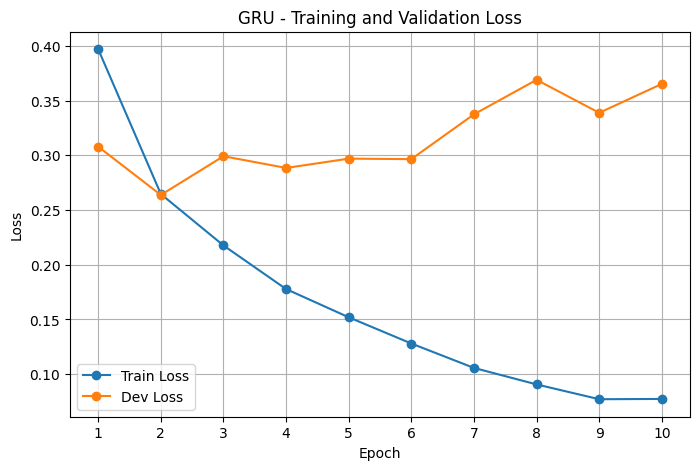

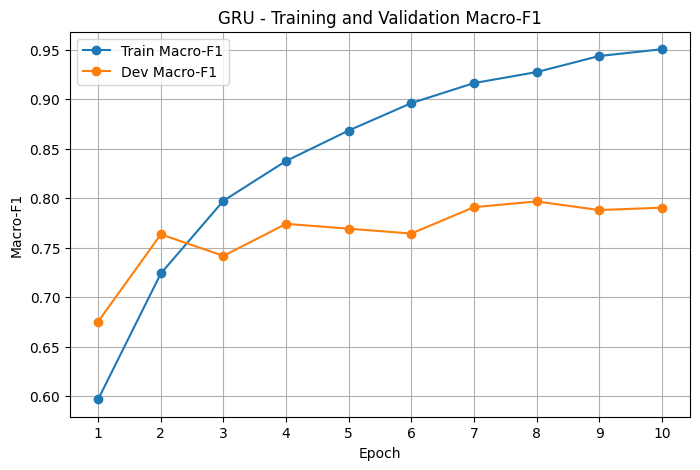

In [43]:
import matplotlib.pyplot as plt

epochs_range = [
    item["epoch"] for item in gru_history
]

train_losses = [
    item["train_loss"] for item in gru_history
]

dev_losses = [
    item["dev_loss"] for item in gru_history
]

train_f1s = [
    item["train_f1"] for item in gru_history
]

dev_f1s = [
    item["dev_f1"] for item in gru_history
]

# Loss curve
plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_losses, marker="o", label="Train Loss")
plt.plot(epochs_range, dev_losses, marker="o", label="Dev Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GRU - Training and Validation Loss")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)
plt.show()

# Macro-F1 curve
plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_f1s, marker="o", label="Train Macro-F1")
plt.plot(epochs_range, dev_f1s, marker="o", label="Dev Macro-F1")

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("GRU - Training and Validation Macro-F1")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)
plt.show()

===== GRU TEST RESULTS =====
Accuracy : 0.9024
Precision: 0.7723
Recall   : 0.7310
Macro-F1 : 0.7463

Classification Report:
              precision    recall  f1-score   support

    negative     0.9062    0.9390    0.9223      1409
     neutral     0.4821    0.3234    0.3871       167
    positive     0.9285    0.9308    0.9296      1590

    accuracy                         0.9024      3166
   macro avg     0.7723    0.7310    0.7463      3166
weighted avg     0.8950    0.9024    0.8977      3166



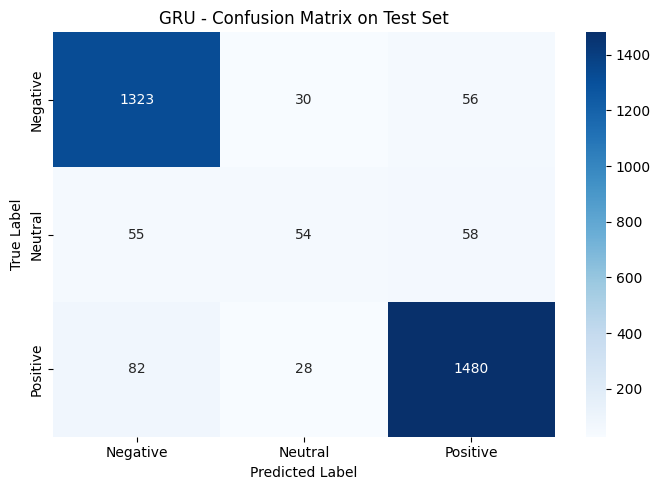

In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns

# Load checkpoint tốt nhất
gru_model.load_state_dict(
    torch.load(
        "best_gru_vsfc.pt",
        map_location=DEVICE,
        weights_only=True
    )
)

gru_model.eval()

# Test evaluation
gru_test_result = run_epoch(
    model=gru_model,
    loader=test_loader,
    criterion=criterion_gru,
    optimizer=None
)

gru_y_true = gru_test_result["labels"]
gru_y_pred = gru_test_result["predictions"]

gru_accuracy = accuracy_score(gru_y_true, gru_y_pred)

gru_precision = precision_score(
    gru_y_true, gru_y_pred,
    average="macro",
    zero_division=0
)

gru_recall = recall_score(
    gru_y_true, gru_y_pred,
    average="macro",
    zero_division=0
)

gru_macro_f1 = f1_score(
    gru_y_true, gru_y_pred,
    average="macro",
    zero_division=0
)

print("===== GRU TEST RESULTS =====")
print(f"Accuracy : {gru_accuracy:.4f}")
print(f"Precision: {gru_precision:.4f}")
print(f"Recall   : {gru_recall:.4f}")
print(f"Macro-F1 : {gru_macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    gru_y_true,
    gru_y_pred,
    labels=[0, 1, 2],
    target_names=["negative", "neutral", "positive"],
    digits=4,
    zero_division=0
))

# Confusion Matrix
cm_gru = confusion_matrix(
    gru_y_true,
    gru_y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gru,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("GRU - Confusion Matrix on Test Set")
plt.tight_layout()
plt.show()

In [45]:
import pandas as pd
import numpy as np

lstm_avg_time = np.mean([
    293.96, 232.60, 209.17, 216.20, 207.80,
    251.69, 209.68, 207.95, 207.15, 208.19
])

gru_avg_time = np.mean([
    item["epoch_time"] for item in gru_history
])

comparison = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": 0.8977,
        "Precision": 0.8189,
        "Recall": 0.6929,
        "Macro-F1": 0.7159,
        "Parameters": "N/A",
        "Avg Epoch Time (s)": "N/A",
        "Best Epoch": "N/A"
    },
    {
        "Model": "LSTM 5 layers",
        "Accuracy": 0.9024,
        "Precision": 0.7767,
        "Recall": 0.7450,
        "Macro-F1": 0.7580,
        "Parameters": f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}",
        "Avg Epoch Time (s)": round(lstm_avg_time, 2),
        "Best Epoch": 5
    },
    {
        "Model": "GRU 5 layers",
        "Accuracy": gru_accuracy,
        "Precision": gru_precision,
        "Recall": gru_recall,
        "Macro-F1": gru_macro_f1,
        "Parameters": f"{gru_params:,}",
        "Avg Epoch Time (s)": round(gru_avg_time, 2),
        "Best Epoch": best_gru_epoch
    }
])

display(comparison)

,Model,Accuracy,Precision,Recall,Macro-F1,Parameters,Avg Epoch Time (s),Best Epoch
0,TF-IDF + Logistic Regression,0.897700,0.818900,0.692900,0.715900,N/A,N/A,N/A
1,LSTM 5 layers,0.902400,0.776700,0.745000,0.758000,"3,138,607",224.44,5
2,GRU 5 layers,0.902401,0.772263,0.731045,0.746339,"2,469,423",168.09,8


In [46]:
lstm_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

gru_params = sum(
    p.numel() for p in gru_model.parameters()
    if p.requires_grad
)

print("LSTM parameters:", f"{lstm_params:,}")
print("GRU parameters:", f"{gru_params:,}")

print(
    "Parameter reduction:",
    f"{(1 - gru_params / lstm_params) * 100:.2f}%"
)

LSTM parameters: 3,138,607
GRU parameters: 2,469,423
Parameter reduction: 21.32%


### Bảng so sánh kết quả các mô hình

| Model | Accuracy | Precision | Recall | Macro-F1 | Parameters | Avg Epoch Time (s) | Best Epoch |
|---|---:|---:|---:|---:|---:|---:|---:|
| TF-IDF + Logistic Regression | 0.8977 | 0.8189 | 0.6929 | 0.7159 | N/A | N/A | N/A |
| LSTM 5 layers | 0.9024 | 0.7767 | 0.7450 | **0.7580** | 3,138,607 | 224.44 | 5 |
| GRU 5 layers | 0.9024 | 0.7723 | 0.7310 | 0.7463 | 2,469,423 | 168.09 | 8 |

### Nhận xét kết quả

1. **Hiệu quả phân loại:** LSTM đạt Macro-F1 = 0.7580, cao hơn GRU (0.7463) và TF-IDF + Logistic Regression (0.7159). Điều này cho thấy LSTM có khả năng cân bằng hiệu quả phân loại giữa ba lớp tốt hơn trong thí nghiệm này.

2. **Số lượng tham số:** GRU có 2,469,423 tham số, ít hơn khoảng 21.32% so với LSTM (3,138,607 tham số). Điều này cho thấy GRU có kiến trúc gọn nhẹ hơn.

3. **Thời gian huấn luyện:** GRU mất trung bình 168.09 giây/epoch, nhanh hơn khoảng 25.1% so với LSTM (224.44 giây/epoch).

4. **Khả năng tổng quát hóa:** LSTM đạt kết quả tốt nhất trên tập dev tại epoch 5, trong khi GRU đạt kết quả tốt nhất tại epoch 8. Cả hai mô hình đều có dấu hiệu overfitting khi Train F1 tiếp tục tăng nhưng Dev F1 không tăng tương ứng.

### Kết luận

Trong thí nghiệm này, LSTM đạt hiệu quả phân loại tốt hơn GRU xét theo Macro-F1 trên tập test. Ngược lại, GRU có lợi thế về số lượng tham số và thời gian huấn luyện. Do đó, việc lựa chọn giữa hai kiến trúc phụ thuộc vào mục tiêu ưu tiên: LSTM phù hợp hơn khi ưu tiên hiệu quả phân loại, còn GRU là lựa chọn đáng cân nhắc khi cần giảm chi phí tính toán.

**Lưu ý:** Accuracy, Precision, Recall và Macro-F1 được tính trên tập test. Best Epoch được xác định dựa trên Macro-F1 của tập dev, không phải tập test.

### Bài 3: Xây dựng kiến trúc Encoder trong đó Encoder gồm 5 lớp BiLSTM với hidden size là 256 cho bài toán nhận diện thực thể (Name Entity Recognition). Huấn luyện mô hình trên bộ dữ liệu PhoNER và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [53]:
import json

def load_jsonl(path):
    data = []

    with open(path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            line = line.strip()

            if not line:
                continue

            try:
                data.append(json.loads(line))
            except json.JSONDecodeError as e:
                raise ValueError(
                    f"Lỗi JSON tại {path}, dòng {line_no}: {e}"
                )

    return data


train_path = DATA / "phoner" / "train_syllable.json"
dev_path = DATA / "phoner" / "dev_syllable.json"
test_path = DATA / "phoner" / "test_syllable.json"

train_data = load_jsonl(train_path)
dev_data = load_jsonl(dev_path)
test_data = load_jsonl(test_path)

print("Train:", len(train_data))
print("Dev:", len(dev_data))
print("Test:", len(test_data))

print("\nSample:")
print(train_data[0])

Train: 5027
Dev: 2000
Test: 3000

Sample:
{'words': ['Đồng', 'thời', ',', 'bệnh', 'viện', 'tiếp', 'tục', 'thực', 'hiện', 'các', 'biện', 'pháp', 'phòng', 'chống', 'dịch', 'bệnh', 'COVID', '-', '19', 'theo', 'hướng', 'dẫn', 'của', 'Bộ', 'Y', 'tế', '.'], 'tags': ['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-ORGANIZATION', 'I-ORGANIZATION', 'I-ORGANIZATION', 'O']}


In [55]:
from collections import Counter
import torch
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader

# =========================
# 1. KIỂM TRA DỮ LIỆU
# =========================

for split_name, dataset in [
    ("Train", train_data),
    ("Dev", dev_data),
    ("Test", test_data)
]:
    for sample in dataset:
        assert len(sample["words"]) == len(sample["tags"]), (
            f"Words/tags mismatch in {split_name}"
        )

print("All samples have matching words and tags.")

# =========================
# 2. XÂY DỰNG WORD VOCAB
# =========================

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

word_counter = Counter(
    word
    for sample in train_data
    for word in sample["words"]
)

word2id = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word in word_counter:
    if word not in word2id:
        word2id[word] = len(word2id)

PAD_ID = word2id[PAD_TOKEN]
UNK_ID = word2id[UNK_TOKEN]

VOCAB_SIZE = len(word2id)

# =========================
# 3. XÂY DỰNG TAG MAPPING
# =========================

tag_set = {
    tag
    for sample in train_data
    for tag in sample["tags"]
}

# O được gán ID 0, các nhãn còn lại sắp xếp ổn định
tag_list = ["O"] + sorted(tag_set - {"O"})

tag2id = {
    tag: idx
    for idx, tag in enumerate(tag_list)
}

id2tag = {
    idx: tag
    for tag, idx in tag2id.items()
}

NUM_TAGS = len(tag2id)

print("\n===== VOCABULARY =====")
print("Vocabulary size:", VOCAB_SIZE)
print("PAD_ID:", PAD_ID)
print("UNK_ID:", UNK_ID)

print("\n===== BIO TAGS =====")
print("Number of tags:", NUM_TAGS)

for tag, idx in tag2id.items():
    print(f"{idx:2d}: {tag}")

assert NUM_TAGS == 21, (
    f"Expected 21 tags, but found {NUM_TAGS}. "
    "Check the tag distribution before training."
)

# =========================
# 4. DATASET
# =========================

class PhoNERDataset(Dataset):
    def __init__(self, data, word2id, tag2id):
        self.data = data
        self.word2id = word2id
        self.tag2id = tag2id

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]

        words = sample["words"]
        tags = sample["tags"]

        input_ids = [
            self.word2id.get(word, UNK_ID)
            for word in words
        ]

        label_ids = [
            self.tag2id[tag]
            for tag in tags
        ]

        return (
            torch.tensor(input_ids, dtype=torch.long),
            torch.tensor(label_ids, dtype=torch.long),
            len(input_ids)
        )

# =========================
# 5. COLLATE FUNCTION
# =========================

def collate_fn(batch):
    input_ids, label_ids, lengths = zip(*batch)

    input_ids = pad_sequence(
        input_ids,
        batch_first=True,
        padding_value=PAD_ID
    )

    label_ids = pad_sequence(
        label_ids,
        batch_first=True,
        padding_value=-100
    )

    lengths = torch.tensor(lengths, dtype=torch.long)

    return input_ids, label_ids, lengths

# =========================
# 6. DATALOADERS
# =========================

BATCH_SIZE = 32

train_dataset = PhoNERDataset(train_data, word2id, tag2id)
dev_dataset = PhoNERDataset(dev_data, word2id, tag2id)
test_dataset = PhoNERDataset(test_data, word2id, tag2id)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

# =========================
# 7. KIỂM TRA BATCH
# =========================

xb, yb, lengths = next(iter(train_loader))

print("\n===== DATALOADER CHECK =====")
print("Input shape:", xb.shape)
print("Label shape:", yb.shape)
print("Lengths shape:", lengths.shape)
print("First sequence length:", lengths[0].item())

print("\nFirst sequence:")
print(xb[0, :lengths[0]].tolist())

print("\nFirst labels:")
print([
    id2tag[tag_id.item()]
    for tag_id in yb[0, :lengths[0]]
])

print("\n===== DATASET SIZES =====")
print("Train:", len(train_dataset))
print("Dev:", len(dev_dataset))
print("Test:", len(test_dataset))

All samples have matching words and tags.

===== VOCABULARY =====
Vocabulary size: 3967
PAD_ID: 0
UNK_ID: 1

===== BIO TAGS =====
Number of tags: 21
 0: O
 1: B-AGE
 2: B-DATE
 3: B-GENDER
 4: B-JOB
 5: B-LOCATION
 6: B-NAME
 7: B-ORGANIZATION
 8: B-PATIENT_ID
 9: B-SYMPTOM_AND_DISEASE
10: B-TRANSPORTATION
11: I-AGE
12: I-DATE
13: I-GENDER
14: I-JOB
15: I-LOCATION
16: I-NAME
17: I-ORGANIZATION
18: I-PATIENT_ID
19: I-SYMPTOM_AND_DISEASE
20: I-TRANSPORTATION

===== DATALOADER CHECK =====
Input shape: torch.Size([32, 106])
Label shape: torch.Size([32, 106])
Lengths shape: torch.Size([32])
First sequence length: 37

First sequence:
[2223, 1308, 456, 4, 71, 1125, 379, 838, 119, 90, 402, 403, 281, 654, 150, 190, 191, 122, 93, 731, 5, 33, 1227, 4, 193, 1178, 902, 135, 64, 30, 262, 561, 121, 109, 449, 450, 27]

First labels:
['O', 'B-DATE', 'I-DATE', 'O', 'O', 'O', 'O', 'B-AGE', 'O', 'O', 'B-LOCATION', 'I-LOCATION', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-PATIENT_ID', 'O', 'O', 'O

In [56]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class BiLSTM_NER(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=300,
        hidden_size=256,
        num_layers=5,
        num_classes=21,
        dropout=0.3,
        padding_idx=0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=padding_idx
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, _ = self.lstm(packed)

        output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=input_ids.size(1)
        )

        output = self.dropout(output)

        logits = self.fc(output)

        return logits

In [57]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

EMBED_DIM = 300
HIDDEN_SIZE = 256
NUM_LAYERS = 5
DROPOUT = 0.3
LEARNING_RATE = 0.001
EPOCHS = 10

ner_model = BiLSTM_NER(
    vocab_size=VOCAB_SIZE,
    embed_dim=EMBED_DIM,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    num_classes=NUM_TAGS,
    dropout=DROPOUT,
    padding_idx=PAD_ID
).to(DEVICE)

criterion = nn.CrossEntropyLoss(ignore_index=-100)

optimizer = torch.optim.Adam(
    ner_model.parameters(),
    lr=LEARNING_RATE
)

total_params = sum(
    p.numel()
    for p in ner_model.parameters()
    if p.requires_grad
)

print("Device:", DEVICE)
print("Number of tags:", NUM_TAGS)
print("Trainable parameters:", f"{total_params:,}")

Device: cpu
Number of tags: 21
Trainable parameters: 8,651,497


In [58]:
%pip install seqeval

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from seqeval.scheme import IOB2
import time
import copy

In [60]:
def evaluate_ner(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0

    all_true_tags = []
    all_pred_tags = []

    with torch.no_grad():
        for input_ids, labels, lengths in loader:

            input_ids = input_ids.to(device)
            labels = labels.to(device)

            logits = model(input_ids, lengths)

            loss = criterion(
                logits.reshape(-1, logits.size(-1)),
                labels.reshape(-1)
            )

            total_loss += loss.item()

            predictions = torch.argmax(logits, dim=-1)

            # Cắt theo độ dài thật trước khi chuyển ID thành tag
            for i, length in enumerate(lengths.tolist()):

                true_ids = labels[i, :length].cpu().tolist()
                pred_ids = predictions[i, :length].cpu().tolist()

                true_tags = [
                    id2tag[tag_id]
                    for tag_id in true_ids
                ]

                pred_tags = [
                    id2tag[tag_id]
                    for tag_id in pred_ids
                ]

                all_true_tags.append(true_tags)
                all_pred_tags.append(pred_tags)

    avg_loss = total_loss / len(loader)

    entity_precision = precision_score(
        all_true_tags,
        all_pred_tags,
        mode="strict",
        scheme=IOB2,
        zero_division=0
    )

    entity_recall = recall_score(
        all_true_tags,
        all_pred_tags,
        mode="strict",
        scheme=IOB2,
        zero_division=0
    )

    entity_f1 = f1_score(
        all_true_tags,
        all_pred_tags,
        mode="strict",
        scheme=IOB2,
        zero_division=0
    )

    return (
        avg_loss,
        entity_precision,
        entity_recall,
        entity_f1,
        all_true_tags,
        all_pred_tags
    )

In [61]:
def train_one_epoch_ner(
    model,
    loader,
    criterion,
    optimizer,
    device
):
    model.train()

    total_loss = 0.0

    for input_ids, labels, lengths in loader:

        input_ids = input_ids.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(input_ids, lengths)

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            labels.reshape(-1)
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [62]:
history = []

best_dev_f1 = -1.0
best_epoch = 0

best_model_state = None

for epoch in range(EPOCHS):

    start_time = time.time()

    train_loss = train_one_epoch_ner(
        ner_model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    (
        dev_loss,
        dev_precision,
        dev_recall,
        dev_f1,
        _,
        _
    ) = evaluate_ner(
        ner_model,
        dev_loader,
        criterion,
        DEVICE
    )

    epoch_time = time.time() - start_time

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "dev_loss": dev_loss,
        "dev_precision": dev_precision,
        "dev_recall": dev_recall,
        "dev_f1": dev_f1,
        "epoch_time": epoch_time
    })

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Dev Loss: {dev_loss:.4f} | "
        f"Dev P: {dev_precision:.4f} | "
        f"Dev R: {dev_recall:.4f} | "
        f"Dev Entity-F1: {dev_f1:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

    if dev_f1 > best_dev_f1:

        best_dev_f1 = dev_f1
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            ner_model.state_dict()
        )

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "best_dev_f1": best_dev_f1,
            "word2id": word2id,
            "tag2id": tag2id,
            "config": {
                "embed_dim": EMBED_DIM,
                "hidden_size": HIDDEN_SIZE,
                "num_layers": NUM_LAYERS,
                "dropout": DROPOUT
            }
        }, "best_bilstm_ner.pt")

print("\n===== TRAINING COMPLETED =====")
print("Best epoch:", best_epoch)
print("Best Dev Entity-F1:", f"{best_dev_f1:.4f}")
print("Saved checkpoint: best_bilstm_ner.pt")

Epoch 01/10 | Train Loss: 0.7072 | Dev Loss: 0.3170 | Dev P: 0.6886 | Dev R: 0.6396 | Dev Entity-F1: 0.6632 | Time: 561.90s
Epoch 02/10 | Train Loss: 0.1669 | Dev Loss: 0.1904 | Dev P: 0.8504 | Dev R: 0.8275 | Dev Entity-F1: 0.8388 | Time: 515.00s
Epoch 03/10 | Train Loss: 0.0901 | Dev Loss: 0.1619 | Dev P: 0.8880 | Dev R: 0.8473 | Dev Entity-F1: 0.8672 | Time: 508.64s
Epoch 04/10 | Train Loss: 0.0588 | Dev Loss: 0.1575 | Dev P: 0.8988 | Dev R: 0.8612 | Dev Entity-F1: 0.8796 | Time: 511.01s
Epoch 05/10 | Train Loss: 0.0480 | Dev Loss: 0.1681 | Dev P: 0.9046 | Dev R: 0.8800 | Dev Entity-F1: 0.8922 | Time: 516.46s
Epoch 06/10 | Train Loss: 0.0352 | Dev Loss: 0.1569 | Dev P: 0.9126 | Dev R: 0.8827 | Dev Entity-F1: 0.8974 | Time: 520.85s
Epoch 07/10 | Train Loss: 0.0313 | Dev Loss: 0.1550 | Dev P: 0.8951 | Dev R: 0.8969 | Dev Entity-F1: 0.8960 | Time: 527.34s
Epoch 08/10 | Train Loss: 0.0260 | Dev Loss: 0.1820 | Dev P: 0.8969 | Dev R: 0.8842 | Dev Entity-F1: 0.8905 | Time: 530.67s
Epoch 09

In [63]:
# =========================
# 1. LOAD BEST CHECKPOINT
# =========================

checkpoint = torch.load(
    "best_bilstm_ner.pt",
    map_location=DEVICE,
    weights_only=False
)

ner_model.load_state_dict(
    checkpoint["model_state_dict"]
)

ner_model.eval()

print("Loaded epoch:", checkpoint["epoch"])
print("Best Dev Entity-F1:", checkpoint["best_dev_f1"])

# =========================
# 2. EVALUATE TEST
# =========================

(
    test_loss,
    test_precision,
    test_recall,
    test_f1,
    test_true_tags,
    test_pred_tags
) = evaluate_ner(
    ner_model,
    test_loader,
    criterion,
    DEVICE
)

print("\n===== TEST RESULTS =====")
print(f"Test Loss      : {test_loss:.4f}")
print(f"Precision      : {test_precision:.4f}")
print(f"Recall         : {test_recall:.4f}")
print(f"Micro Entity-F1: {test_f1:.4f}")

# =========================
# 3. ENTITY-LEVEL REPORT
# =========================

report = classification_report(
    test_true_tags,
    test_pred_tags,
    mode="strict",
    scheme=IOB2,
    digits=4,
    zero_division=0
)

print("\n===== ENTITY CLASSIFICATION REPORT =====")
print(report)

Loaded epoch: 6
Best Dev Entity-F1: 0.8974236965535993

===== TEST RESULTS =====
Test Loss      : 0.1942
Precision      : 0.9061
Recall         : 0.8664
Micro Entity-F1: 0.8858

===== ENTITY CLASSIFICATION REPORT =====
                     precision    recall  f1-score   support

                AGE     0.8925    0.9553    0.9228       582
               DATE     0.9669    0.9371    0.9518      1654
             GENDER     0.9068    0.9264    0.9165       462
                JOB     0.5250    0.3642    0.4300       173
           LOCATION     0.9211    0.8827    0.9015      4441
               NAME     0.6667    0.3774    0.4819       318
       ORGANIZATION     0.8495    0.7613    0.8030       771
         PATIENT_ID     0.9402    0.9641    0.9520      2005
SYMPTOM_AND_DISEASE     0.8223    0.7579    0.7888      1136
     TRANSPORTATION     0.8613    0.7720    0.8142       193

          micro avg     0.9061    0.8664    0.8858     11735
          macro avg     0.8352    0.7698    0.7

In [64]:
(
    dev_loss,
    dev_precision,
    dev_recall,
    dev_f1,
    dev_true_tags,
    dev_pred_tags
) = evaluate_ner(
    ner_model,
    dev_loader,
    criterion,
    DEVICE
)

print("Best checkpoint Dev Entity-F1:", dev_f1)

Best checkpoint Dev Entity-F1: 0.8974236965535993


In [65]:
def extract_entities(tags):
    """
    Trích xuất entity theo IOB2.
    Kết quả: (entity_type, start, end)
    end là exclusive.
    """

    entities = []

    current_type = None
    start = None

    for i, tag in enumerate(tags + ["O"]):

        if tag == "O":
            if current_type is not None:
                entities.append((current_type, start, i))
                current_type = None
                start = None
            continue

        prefix, entity_type = tag.split("-", 1)

        if prefix == "B":
            if current_type is not None:
                entities.append((current_type, start, i))

            current_type = entity_type
            start = i

        elif prefix == "I":
            if current_type != entity_type:
                if current_type is not None:
                    entities.append((current_type, start, i))

                current_type = entity_type
                start = i

    return entities

In [66]:
error_examples = {
    "False Negative": [],
    "False Positive": [],
    "Boundary Error": [],
    "Entity Type Error": []
}

for idx, (true_tags, pred_tags) in enumerate(
    zip(dev_true_tags, dev_pred_tags)
):
    true_entities = extract_entities(true_tags)
    pred_entities = extract_entities(pred_tags)

    true_set = set(true_entities)
    pred_set = set(pred_entities)

    missed = true_set - pred_set
    extra = pred_set - true_set

    # False Negative
    for entity in missed:
        if len(error_examples["False Negative"]) < 5:
            error_examples["False Negative"].append(
                (idx, entity, true_tags, pred_tags)
            )

    # False Positive
    for entity in extra:
        if len(error_examples["False Positive"]) < 5:
            error_examples["False Positive"].append(
                (idx, entity, true_tags, pred_tags)
            )

    # Boundary Error:
    # Cùng loại, hai khoảng giao nhau nhưng không trùng hoàn toàn
    for true_entity in missed:
        for pred_entity in extra:

            same_type = true_entity[0] == pred_entity[0]

            overlap = (
                true_entity[1] < pred_entity[2]
                and pred_entity[1] < true_entity[2]
            )

            if same_type and overlap:
                if len(error_examples["Boundary Error"]) < 5:
                    error_examples["Boundary Error"].append(
                        (idx, true_entity, pred_entity,
                         true_tags, pred_tags)
                    )
                break

    # Entity Type Error:
    # Cùng phạm vi nhưng khác loại
    for true_entity in missed:
        for pred_entity in extra:

            same_span = (
                true_entity[1] == pred_entity[1]
                and true_entity[2] == pred_entity[2]
            )

            if same_span and true_entity[0] != pred_entity[0]:
                if len(error_examples["Entity Type Error"]) < 5:
                    error_examples["Entity Type Error"].append(
                        (idx, true_entity, pred_entity,
                         true_tags, pred_tags)
                    )
                break

In [67]:
def show_error_examples(error_examples, dev_data):
    for error_type, examples in error_examples.items():

        print("\n" + "=" * 70)
        print(error_type)
        print("=" * 70)

        if not examples:
            print("Không tìm thấy ví dụ.")
            continue

        for example in examples[:3]:

            idx = example[0]

            print(f"\nDev sample: {idx}")
            print("Sentence:")
            print(" ".join(dev_data[idx]["words"]))

            if error_type in [
                "False Negative",
                "False Positive"
            ]:
                print("Entity:", example[1])
            else:
                print("True entity:", example[1])
                print("Pred entity:", example[2])

            print("True tags:")
            print(" ".join(example[-2]))

            print("Pred tags:")
            print(" ".join(example[-1]))


show_error_examples(error_examples, dev_data)


False Negative

Dev sample: 0
Sentence:
Bác sĩ Nguyễn Trung Nguyên , Giám đốc Trung tâm Chống độc , Bệnh viện Bạch Mai , cho biết bệnh nhân được chuyển đến bệnh viện ngày 7/3 , chẩn đoán ngộ độc thuốc điều trị sốt rét chloroquine .
Entity: ('SYMPTOM_AND_DISEASE', 32, 35)
True tags:
O O O O O O O O B-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION O O O O O O O O O O O B-DATE O O O B-SYMPTOM_AND_DISEASE I-SYMPTOM_AND_DISEASE I-SYMPTOM_AND_DISEASE O O O O O O
Pred tags:
O O O O O O O O B-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION I-ORGANIZATION O O O O O O O O O O O B-DATE O O O O O O O O O O O O

Dev sample: 1
Sentence:
" Bệnh nhân 812 " , nam , 62 tuổi , là nhân viên giao bánh tiệm pizza phố Trần Thái Tông , Hà Nội , trú tại quận Bắc Từ Liêm , lây từ " bệnh nhân 447 " ( cũng là nhân viên tiệm bánh , đi du lịch Đà Nẵng ) .
Entit

### Thông tin mô hình BiLSTM-CRF

| Thông số | Giá trị |
|---|---:|
| Model | BiLSTM-CRF |
| Device | CPU |
| Number of Tags | 21 |
| Trainable Parameters | 8,651,497 |
| Average Epoch Time (s) | 518.21 |
| Best Epoch | 6 |
| Best Dev Entity-F1 | 0.8974 |
| Test Micro Entity-F1 | 0.8858 |

### Bảng kết quả đánh giá trên tập Test

| Model | Precision | Recall | Micro Entity-F1 | Parameters | Avg Epoch Time (s) | Best Epoch |
|---|---:|---:|---:|---:|---:|---:|
| BiLSTM-CRF | 0.9061 | 0.8664 | **0.8858** | 8,651,497 | 518.21 | 6 |

### Nhận xét

Mô hình BiLSTM-CRF có 8,651,497 tham số và được huấn luyện trên CPU. Sau 10 epochs, mô hình đạt kết quả tốt nhất trên tập dev tại epoch 6 với Entity-F1 = 0.8974.

Trên tập test, mô hình đạt Precision = 0.9061, Recall = 0.8664 và Micro Entity-F1 = 0.8858. Chênh lệch giữa Dev Entity-F1 tốt nhất và Test Micro Entity-F1 là 0.0116, cho thấy kết quả trên hai tập dữ liệu tương đối gần nhau.